## MTL Trajet: 19 Within Cross Area Mobility Patterns (Flag 19)

### Dataset Overview
Within-area and cross-area Montréal trajectories with purpose, mode, timing, area labels, route directness, GPS positions, and point speeds.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Compare mobility patterns of trajectories remaining within one urban area and those crossing between different areas of Montréal.

Role: Urban mobility-pattern analyst


Category: Within-area and cross-area Montréal trajectories with purpose, mode, timing, area labels, route directness, GPS positions, and point speeds.

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does purpose composition differ between within-area and cross-area trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

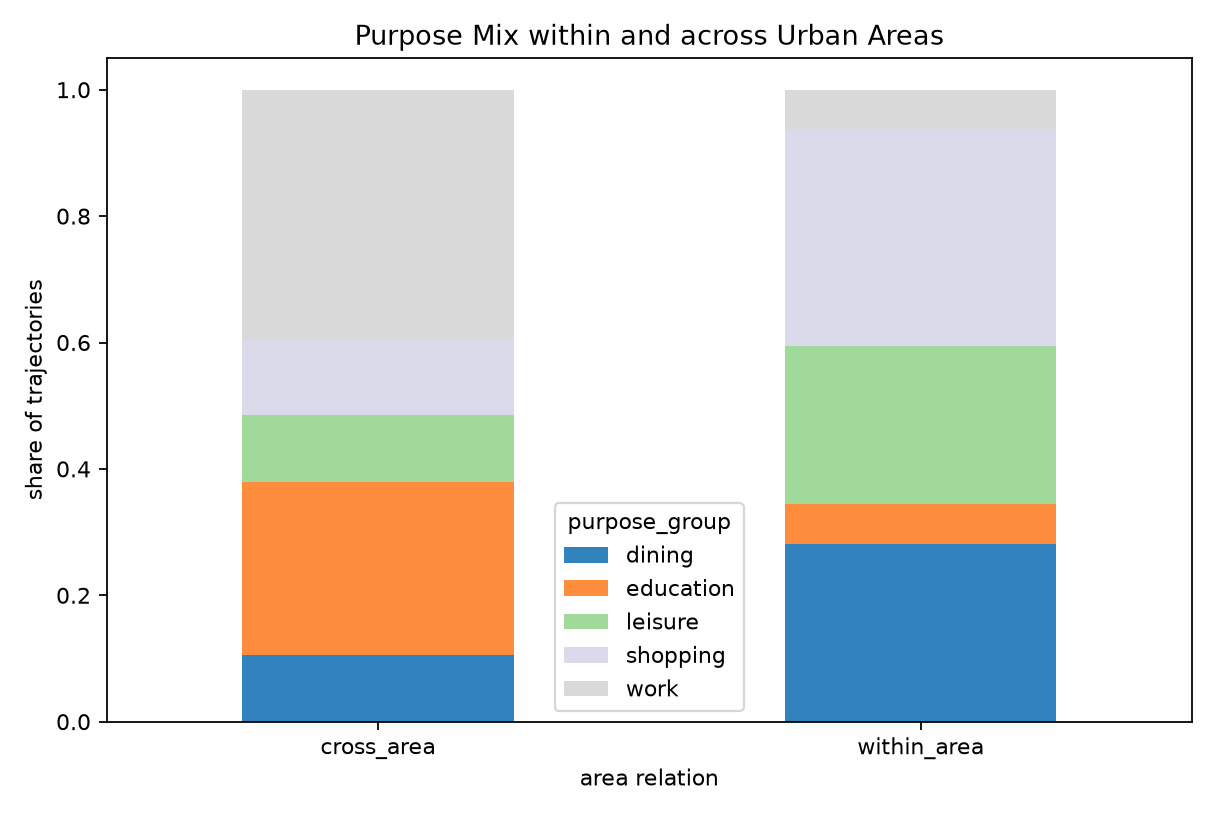

In [ ]:
pd.crosstab(df.area_relation,df.purpose_group,normalize='index')
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/area_relation_purpose.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "area_relation_purpose",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Purpose Mix by Area Relation",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/area_relation_purpose.png"
  },
  "question": "How does purpose composition differ between within-area and cross-area trips?",
  "code": "pd.crosstab(df.area_relation,df.purpose_group,normalize='index')",
  "insight": "Within-area trips are dominated by shopping, dining, and leisure, whereas cross-area trips contain larger shares of work and education travel.",
  "insight_type": "overall_pattern",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 2**: How do mode composition and distance differ between within-area and cross-area trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

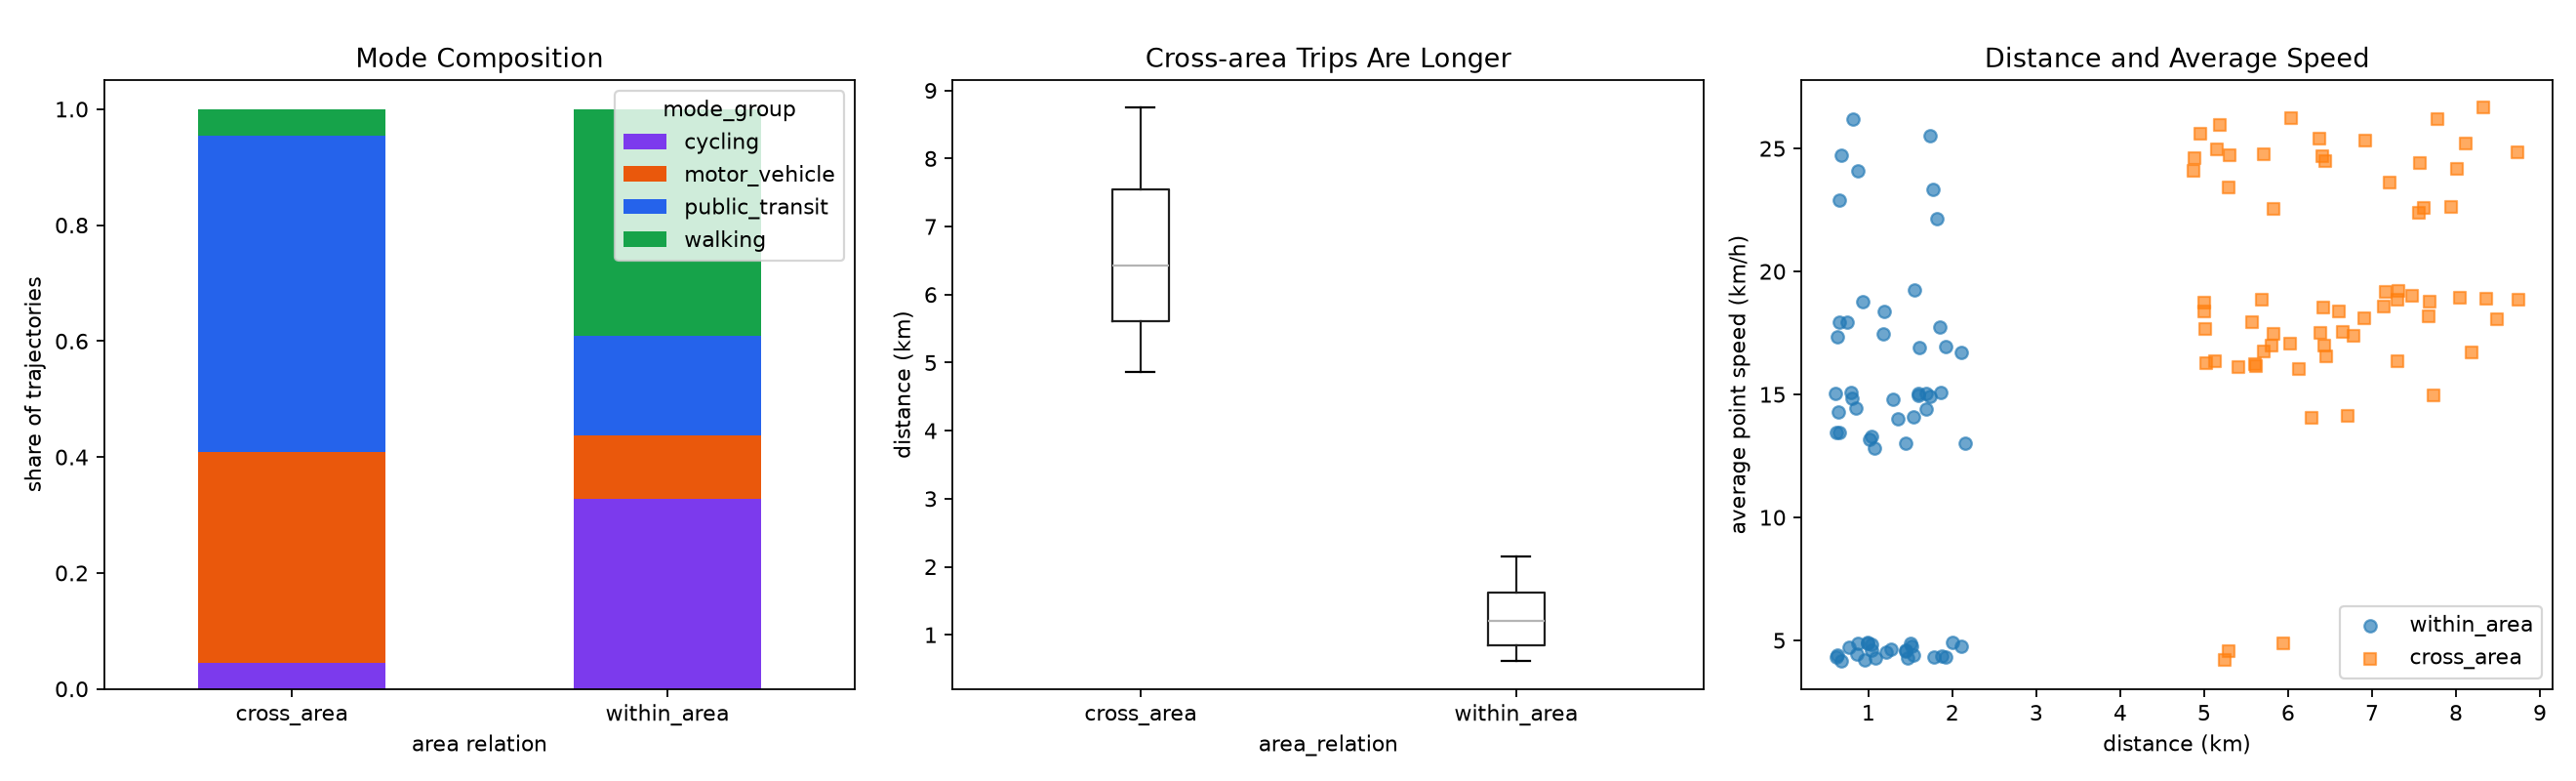

In [ ]:
pd.crosstab(df.area_relation,df.mode_group,normalize='index'); df.groupby('area_relation').distance_km.agg(['median','mean'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/area_relation_distance_speed.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "area_relation_mode_distance",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Mode and Distance by Area Relation",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/area_relation_distance_speed.png"
  },
  "question": "How do mode composition and distance differ between within-area and cross-area trips?",
  "code": "pd.crosstab(df.area_relation,df.mode_group,normalize='index'); df.groupby('area_relation').distance_km.agg(['median','mean'])",
  "insight": "Walking and cycling concentrate in short within-area movements, while public transit and motor vehicles dominate longer cross-area trajectories.",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "transport_mode",
    "trajectory_id",
    "point_speed"
  ]
}

### **Question 3**: When do cross-area work and education trips occur relative to within-area discretionary trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

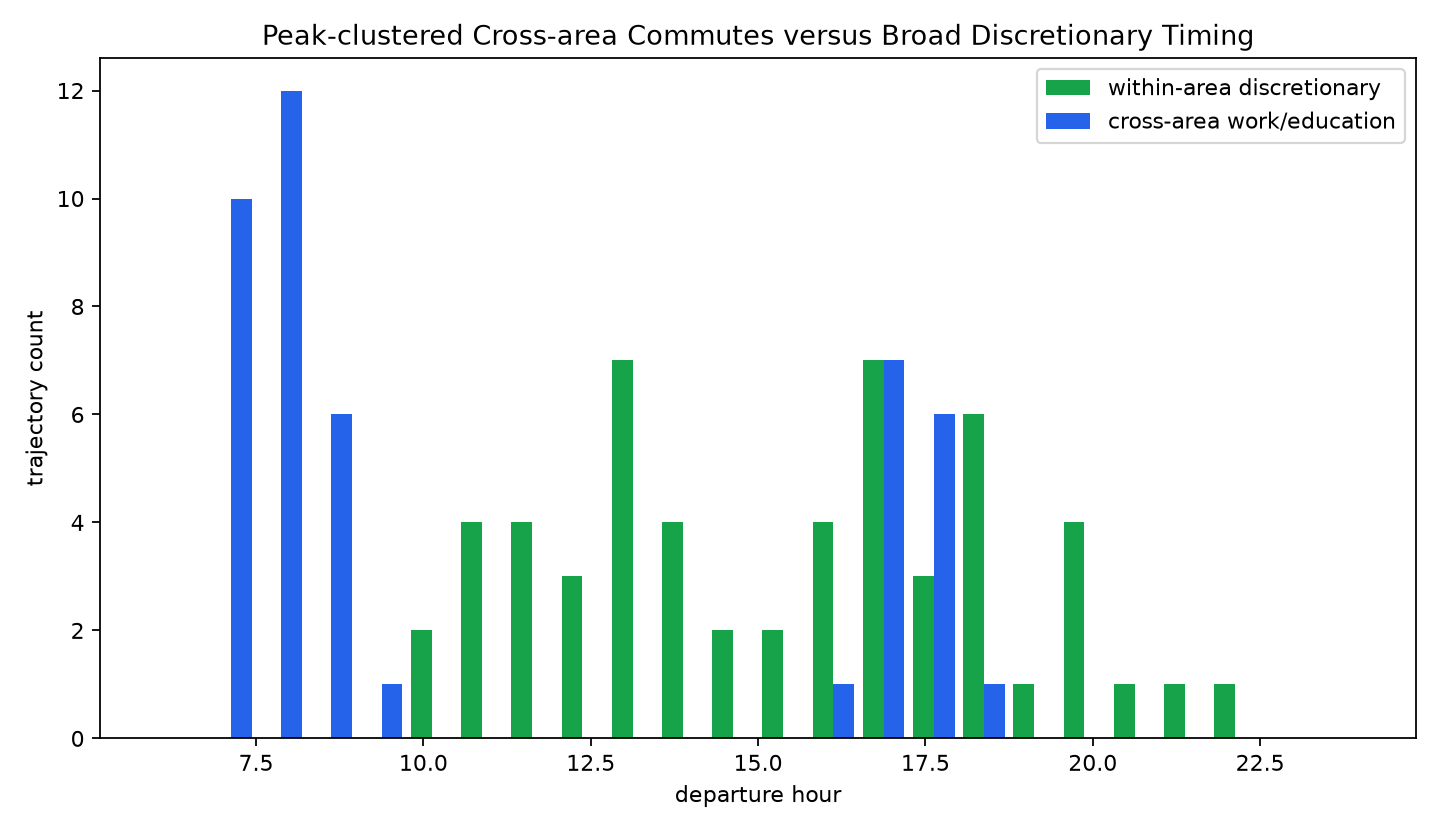

In [ ]:
df.groupby(['area_relation','purpose_group','departure_period']).size()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/area_relation_departure_timing.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "area_relation_departure_time",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Departure Timing by Area Relation and Purpose",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/area_relation_departure_timing.png"
  },
  "question": "When do cross-area work and education trips occur relative to within-area discretionary trips?",
  "code": "df.groupby(['area_relation','purpose_group','departure_period']).size()",
  "insight": "Cross-area work and education trips cluster around morning and evening peaks, whereas within-area discretionary travel is distributed more broadly.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 4**: Which cross-area discretionary trips are unusually late and direct?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

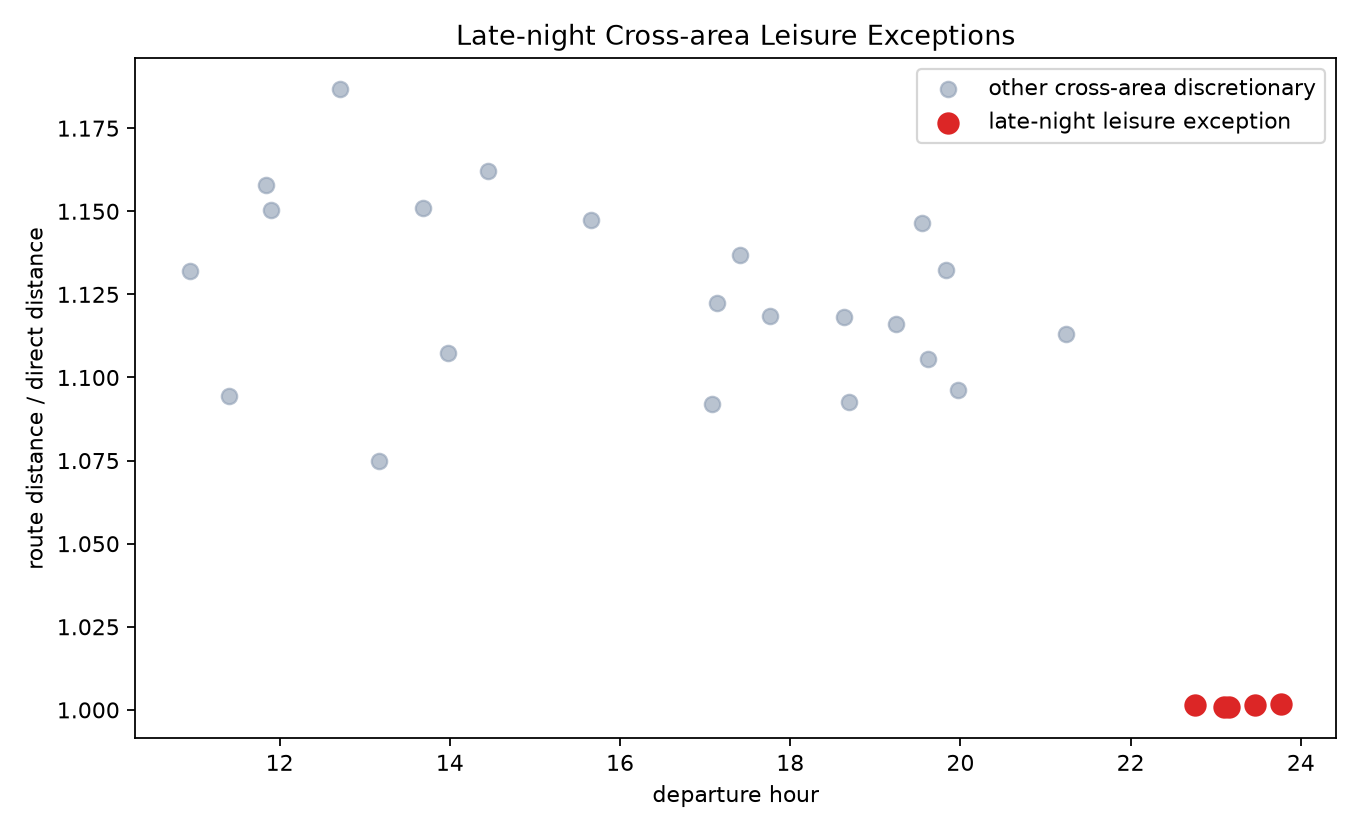

In [ ]:
df[df.area_relation.eq('cross_area')].groupby('is_late_leisure_exception')[['start_hour','route_directness']].agg(['count','median'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/late_leisure_directness_exceptions.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "late_cross_area_leisure_exception",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Late-night Direct Leisure Exceptions",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/late_leisure_directness_exceptions.png"
  },
  "question": "Which cross-area discretionary trips are unusually late and direct?",
  "code": "df[df.area_relation.eq('cross_area')].groupby('is_late_leisure_exception')[['start_hour','route_directness']].agg(['count','median'])",
  "insight": "A small set of cross-area leisure trips occurs late at night and follows unusually direct routes compared with other discretionary travel.",
  "insight_type": "exception_deviation",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 19)

Within-area travel is mainly discretionary and active, while cross-area travel is longer, more commute-oriented, and mostly motorized. Five late-night cross-area leisure trajectories form unusually direct exceptions.